# 01 - Model evaluation

Walk-forward backtest, calibration, and the market comparison, for whatever
leagues you have data for.

**This notebook runs with no setup.** If real data is not present it falls
back to a synthetic league with known ratings, so every cell still executes.
To use real data:

```bash
uv run scripts/update_data.py     # results + odds from football-data.co.uk
uv run scripts/update_xg.py       # match xG from Understat (optional)
```

**Read the market label before quoting any "beats the market" number.**
`b365h/d/a` are collected *days* before kickoff; the real closing line lives
in the `C`-infixed columns. The backtest picks the sharpest closing set that
covers the holdout and records which one in `market_label`.

In [1]:
import warnings, logging
logging.getLogger("soccerdata").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hattrick.experiments import load_leagues
from hattrick.evaluation import walk_forward_backtest

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

matches_by_league, is_real = load_leagues()
print(f"\nUsing {'REAL' if is_real else 'SYNTHETIC'} data: {list(matches_by_league)}")

E0: 1530 matches, xG coverage 100.0% (from matches.csv)
SP1: 1536 matches, xG coverage 100.0% (from matches.csv)
I1: 1530 matches, xG coverage 99.9% (from matches.csv)
D1: 1224 matches, xG coverage 100.0% (from matches.csv)
F1: 1307 matches, xG coverage 99.9% (from matches.csv)

Using REAL data: ['E0', 'SP1', 'I1', 'D1', 'F1']


## Pick the holdout

Everything before `HOLDOUT_START` trains the initial fit; everything after is
scored match by match, with periodic refits so later predictions see newer
form. Nothing after the cutoff ever informs a prediction made before it.

In [2]:
all_dates = pd.concat([m["date"] for m in matches_by_league.values()])
HOLDOUT_START = "2025-08-01" if is_real else str(all_dates.quantile(0.7).date())
print("Holdout starts:", HOLDOUT_START)
print("Data spans:", all_dates.min().date(), "to", all_dates.max().date())

Holdout starts: 2025-08-01
Data spans: 2022-08-05 to 2026-08-24


## Backtest each league

In [3]:
results = {}
for code, m in matches_by_league.items():
    results[code] = walk_forward_backtest(m, holdout_start=HOLDOUT_START)
    print(f"===== {code} =====")
    print(results[code].summary())
    print()

===== E0 =====
Matches evaluated: 387
Model:   log loss=1.0236  Brier=0.6141
Market:  log loss=1.0089  Brier=0.6057 (de-vigged cross-book average CLOSING odds, n=387)
Delta (model - market) log loss: +0.0147  -> market beats model
model - market mean diff: +0.0147 ([-0.0028, +0.0325] CI), p=0.097 -> not significant; market better (n=387)

===== SP1 =====
Matches evaluated: 390
Model:   log loss=0.9795  Brier=0.5812
Market:  log loss=0.9674  Brier=0.5734 (de-vigged cross-book average CLOSING odds, n=390)
Delta (model - market) log loss: +0.0122  -> market beats model
model - market mean diff: +0.0122 ([-0.0019, +0.0262] CI), p=0.094 -> not significant; market better (n=390)

===== I1 =====
Matches evaluated: 389
Model:   log loss=0.9922  Brier=0.5916
Market:  log loss=0.9732  Brier=0.5791 (de-vigged cross-book average CLOSING odds, n=389)
Delta (model - market) log loss: +0.0191  -> market beats model
model - market mean diff: +0.0191 ([+0.0031, +0.0347] CI), p=0.021 -> SIGNIFICANT; mar

## Cross-league summary

`delta` is model log loss minus market log loss: **positive means the market
is better**. Expect positive. The de-vigged closing line is a very strong
forecast, and a Dixon-Coles model on goals alone is not expected to beat it.

In [4]:
rows = []
for code, r in results.items():
    rows.append({"league": code, "n": r.n_matches,
                 "model_log_loss": r.model_log_loss, "model_brier": r.model_brier,
                 "market_log_loss": r.market_log_loss,
                 "delta": (r.model_log_loss - r.market_log_loss)
                          if r.market_log_loss is not None else np.nan,
                 "market_source": r.market_source})
summary = pd.DataFrame(rows)
display(summary.style.format({c: "{:.4f}" for c in
        ["model_log_loss", "model_brier", "market_log_loss", "delta"]}))

,league,n,model_log_loss,model_brier,market_log_loss,delta,market_source
0,E0,387,1.0236,0.6141,1.0089,0.0147,closing_avg
1,SP1,390,0.9795,0.5812,0.9674,0.0122,closing_avg
2,I1,389,0.9922,0.5916,0.9732,0.0191,closing_avg
3,D1,303,0.9739,0.5760,0.9516,0.0224,closing_avg
4,F1,313,0.9939,0.5946,0.9747,0.0192,closing_avg


## Calibration

Log loss is an *average*, and averages hide the failure that matters most for
a forecast anyone acts on: being systematically overconfident in one probability band. A
reliability diagram shows it directly. Points on the diagonal are perfectly
calibrated; below the line means the model claims more confidence than the
outcomes justify.

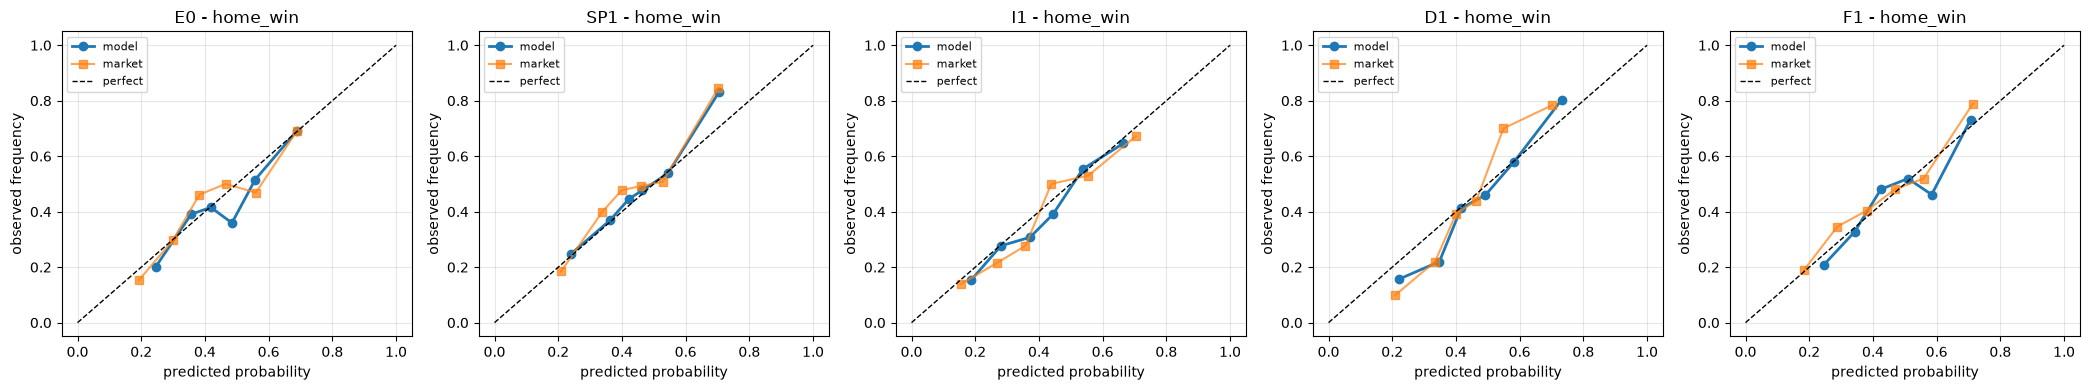

In [5]:
def plot_calibration(res, code, outcome="home_win", ax=None):
    ax = ax or plt.gca()
    for source, style in [("model", dict(marker="o", lw=2)),
                          ("market", dict(marker="s", lw=1.5, alpha=0.7))]:
        try:
            c = res.calibration(outcome=outcome, n_bins=6, strategy="quantile", source=source)
        except Exception:
            continue
        ax.plot(c["mean_predicted"], c["empirical_frequency"], label=source, **style)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
    ax.set(xlabel="predicted probability", ylabel="observed frequency",
           title=f"{code} - {outcome}")
    ax.legend(fontsize=8)

n = len(results)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4), squeeze=False)
for ax, (code, r) in zip(axes[0], results.items()):
    plot_calibration(r, code, ax=ax)
plt.tight_layout(); plt.show()

In [6]:
from hattrick.evaluation import expected_calibration_error

for code, r in results.items():
    parts = []
    for outcome in ["home_win", "draw", "away_win"]:
        ece = expected_calibration_error(
            r.model_probs_list(r.per_match), r.per_match["actual"].tolist(),
            outcome=outcome, n_bins=6, strategy="quantile")
        parts.append(f"{outcome}={ece:.3f}")
    print(f"{code} model ECE:  " + "  ".join(parts))

E0 model ECE:  home_win=0.042  draw=0.033  away_win=0.024
SP1 model ECE:  home_win=0.030  draw=0.055  away_win=0.040
I1 model ECE:  home_win=0.032  draw=0.034  away_win=0.047
D1 model ECE:  home_win=0.051  draw=0.034  away_win=0.046
F1 model ECE:  home_win=0.044  draw=0.039  away_win=0.023


## Where the loss accumulates

A single number cannot tell you whether the model is steadily a bit worse
than the market or occasionally catastrophically wrong. The cumulative
difference does: a straight upward line is a consistent small deficit,
a step is one bad night.

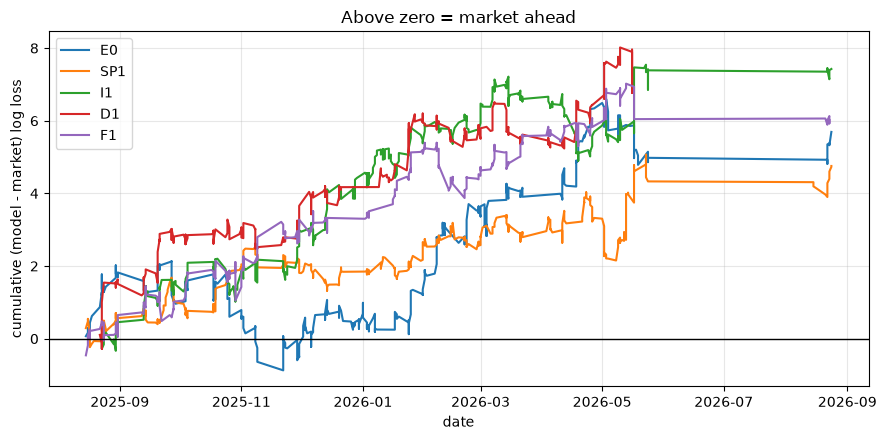

In [7]:
fig, ax = plt.subplots()
for code, r in results.items():
    df = r.per_match.dropna(subset=["market_home_win"]).sort_values("date")
    if df.empty:
        continue
    from hattrick.evaluation import per_match_log_loss
    act = df["actual"].tolist()
    d = per_match_log_loss(r.model_probs_list(df), act) - per_match_log_loss(r.market_probs_list(df), act)
    ax.plot(df["date"], np.cumsum(d), label=code)
ax.axhline(0, color="k", lw=1)
ax.set(xlabel="date", ylabel="cumulative (model - market) log loss",
       title="Above zero = market ahead")
ax.legend(); plt.tight_layout(); plt.show()